# Combinatoria de experimentos

Los notebooks 03 y 04 midieron pocas combinaciones: un slotting, una ventana, un deposito. Este
notebook mide muchas, para saber cuanto de cada resultado depende de cada eleccion: el deposito, el
slotting, el batching, el recorrido, la reposicion, la definicion de frecuencia y los parametros de la
afinidad.

**Como se mide.** Todo con el simulador sobre el periodo de test (el ultimo 20% de los batches), igual
que en el notebook 04. La medida principal es la caminata media por batch, en pulgadas.

**Contenido.**
0. Configuracion.
1. Los factores: que es cada uno, que valores toma y a que afecta.
2. El diseno: por que una grilla mas barridos, y la lista de tareas.
3. La corrida.
4. Controles.
5. Bloque A: slotting por batching por recorrido, en los cuatro depositos.
6. Bloque B: definicion de frecuencia.
7. Bloque C: parametros del QAP (`swap_search`).
8. Bloque D: politica de reposicion.
9. Lectura.

## 0. Configuracion

In [1]:
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import PROJECT_ROOT
from abs_affinity_based_slotting.experiments import (EvalSpec, InstanceSpec, SlottingSpec, Task,
                                                     run_tasks, load_results, load_batches)

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

OUT = PROJECT_ROOT / "results" / "05_combinatoria"   # resultados (fuera de git)

## 1. Los factores

Cada corrida combina un valor de cada factor. Los factores se agrupan por la etapa en la que actuan:
la instancia (los datos del problema), el plan de slotting, y la evaluacion del plan en la simulacion.

**Deposito.** Los cuatro de `data/v2`, con seis meses de historia cada uno.

| deposito | pasillos | que lo distingue |
|---|---|---|
| `small` | 4 | el mas chico |
| `medium` | 8 | el de los notebooks 03 y 04 |
| `medium-alpha-1.3` | 8 | `medium` generado con la demanda mas concentrada en pocos SKUs |
| `big` | 16 | el mas grande |

**Frecuencia $f_i$** (instancia). Que se cuenta como demanda de un SKU en train:

| valor | que cuenta |
|---|---|
| `pick_lines` | lineas de picking (la de todos los notebooks anteriores) |
| `unique_orders` | ordenes distintas que lo piden |
| `unique_batches` | batches distintos que lo visitan |
| `total_units` | unidades |

**Afinidad $a_{ij}$** (instancia). Cuanto aparecen juntos dos SKUs en train. Solo la usan `swap_search`
y la reposicion `objective_greedy`.

| parametro | valores | que es |
|---|---|---|
| metrica | `jaccard`, `cosine`, `cooccurrence` | como se normaliza el conteo de apariciones juntas |
| unidad | `order_id`, `batch_id` | aparecer juntos en la misma orden, o en el mismo batch |
| filtro | `top_k:5`, `top_k:10`, `top_k:20`, `mutual_top_k:10`, `none` | cuantos vecinos se conservan por SKU |
| normalizacion | si, no | si $f$ y $a$ se pasan a proporciones para que $L$ y $Q$ queden en la misma escala |

**Distancia entre productos $D$** (instancia). La que cobra el termino cuadratico de `swap_search`:
`walking` (caminando de bay a bay) o `aisle` (cero en el mismo pasillo, un pasillo entero si no).

**Slotting** (plan).

| plan | que hace |
|---|---|
| vigente | cada SKU donde estaba al corte |
| `demand_greedy` | SKUs por $f_i$ descendente a ubicaciones por distancia al dock ascendente |
| `linear_assignment` | el optimo exacto de $L = \sum_i f_i\, c_{x_i}$ (algoritmo hungaro); solo hasta `medium` por memoria |
| `aisle_fill` | SKUs por $f_i$ descendente, llenando un pasillo entero antes del siguiente |
| `merchant_aisle_fill` | igual, con los SKUs agrupados por merchant (merchants por demanda total) |
| `bilevel` | agrupa los SKUs (por merchant, o en clases A/B/C por demanda acumulada 80% y 95%), un solver le da a cada grupo un bloque de ubicaciones, y adentro de cada bloque aplica `demand_greedy` |
| `swap_search` | parte de un plan inicial y hace intercambios y mudanzas que bajan $C = \lambda L + (1 - \lambda) Q$ |

`bilevel` reparte los bloques minimizando $\sum_{l,g} f_g\, \text{costo}_l\, y_{lg}$, con $f_g$ la demanda
del grupo. Con `costo` = distancia al dock los bloques son franjas a igual distancia del dock; con
`costo` = orden de `aisle_fill` los bloques son pasillos consecutivos.

`swap_search` tiene tres parametros propios: $\lambda$; la vecindad (`bay`: puede mover el SKU a
cualquier ubicacion de la bay de un vecino de afinidad; `neighbor`: solo intercambiarlo con el vecino);
y el plan inicial.

**Batching** (evaluacion). La ventana $W$ del notebook 04: cuantos batches FIFO se re-arman juntos
(1, 2, 4, 8, 16, 32; $W = 1$ es FIFO). El algoritmo es siempre `AisleCoverBatching`.

**Recorrido** (evaluacion). `s_shape`, el de la operacion (notebook 04, seccion 1), y `snake`, el que
usaron los resultados anteriores: ordena las bays por pasillo y numero de bay y las une por el camino
mas corto, asi que vuelve al frente por el mismo pasillo y cobra cuanto se entra en cada uno. El
re-batching agrupa siempre con la caminata en S, tambien cuando se mide con `snake`.

**Reposicion** (evaluacion). Adonde va la mercaderia que llega durante el test.

| politica | que hace |
|---|---|
| `home` | a la ubicacion del SKU en el plan (o la libre mas cercana si esta ocupada) |
| `random` | rellena donde esta; si el SKU se quedo sin stock, con probabilidad 0,9 se muda a una ubicacion libre al azar; asi se generaron los datos |
| `objective_greedy` | a la ubicacion libre o propia que menos sube $C$ con $\lambda = 0{,}5$ |

El re-batching lee el pasillo de cada SKU en el plan. Con `random` u `objective_greedy` los SKUs se
mueven durante el test, asi que esa informacion envejece.

## 2. El diseno

Todas las combinaciones de todos los factores son decenas de miles de corridas, y `swap_search` tarda
entre 5 minutos (`small`) y unos 40 (`medium`) por plan. Por eso el diseno tiene dos partes:

- **Una grilla completa** con los factores que mas mueven el resultado en los notebooks 03 y 04:
  deposito, slotting, ventana y recorrido (bloque A).
- **Barridos de a un factor** para el resto: se parte de una configuracion base y se cambia un solo
  factor por vez (bloques B, C y D). Muestran el efecto de cada factor con todo lo demas fijo. No
  muestran como interactuan dos factores barridos entre si.

**Configuracion base.** Frecuencia `pick_lines`; afinidad `jaccard` por orden con `top_k:10`;
normalizacion si; $D$ = `aisle`; reposicion `home`. Para `swap_search`: $\lambda = 0{,}5$, vecindad
`bay`, plan inicial `demand_greedy`. Son las elecciones con las que se llego al final del notebook 04.

`swap_search` se corre en `small`, `medium` y `medium-alpha-1.3`, no en `big`, por tiempo.

In [2]:
# Regimen de esta grilla: el plan se aplica de una vez al corte, la reposicion es `home` y el test es el
# ultimo 20% de los batches. Los valores por defecto del paquete pasaron a ser los de correct_base/
# (deposito real, regla plan_aisle, test del 40%), asi que aca se fijan los de esta grilla.
from functools import partial
InstanceSpec = partial(InstanceSpec, test_size=0.2)
EvalSpec = partial(EvalSpec, start="plan", replenishment="home")

DEPOSITOS = ["small", "medium", "medium-alpha-1.3", "big"]
CON_QAP = ["small", "medium", "medium-alpha-1.3"]          # donde corre swap_search
VENTANAS = (1, 2, 4, 8, 16, 32)
RUTEOS = ("s_shape", "snake")

# Evaluaciones: la grilla completa (bloque A) y una corta para los barridos.
GRILLA = tuple(EvalSpec(window=w, routing=r) for w in VENTANAS for r in RUTEOS)
CORTA = tuple(EvalSpec(window=w, routing=r) for w in (1, 4, 16) for r in RUTEOS)

RAPIDOS = [SlottingSpec("vigente"), SlottingSpec("demand_greedy"), SlottingSpec("aisle_fill"),
           SlottingSpec("merchant_aisle_fill")]
BILEVEL = [SlottingSpec("bilevel", clustering=c, zone_cost=z) for c in ("merchant", "demand_class") for z in ("dock", "aisle_order")]
SWAP_BASE = SlottingSpec("swap_search", lam=0.5, neighborhood="bay", seed="demand_greedy")

**Bloque A, principal.** Deposito por slotting por ventana por recorrido, con la configuracion base.

In [3]:
tareas = []
for d in DEPOSITOS:
    planes = RAPIDOS + BILEVEL + ([SlottingSpec("linear_assignment"), SWAP_BASE] if d in CON_QAP else [])
    tareas += [Task("A", InstanceSpec(d), p, GRILLA) for p in planes]

**Bloque B, frecuencia.** Las otras tres definiciones de $f$ con los tres planes que la usan para
ordenar. Ventanas 1, 4 y 16, recorrido en S. `pick_lines` ya esta en el bloque A.

In [4]:
EVAL_B = tuple(EvalSpec(window=w) for w in (1, 4, 16))
for d in DEPOSITOS:
    for f in ("unique_orders", "unique_batches", "total_units"):
        tareas += [Task("B", InstanceSpec(d, demand_metric=f), SlottingSpec(m), EVAL_B)
                   for m in ("demand_greedy", "aisle_fill", "merchant_aisle_fill")]

**Bloque C, QAP.** Cada fila cambia un solo factor de `swap_search` respecto de la base. La base esta
en el bloque A.

In [5]:
# (factor, valor, cambios en la instancia, cambios en el plan)
VARIANTES_QAP = [
    ("lambda", 0.0, {}, {"lam": 0.0}), ("lambda", 0.25, {}, {"lam": 0.25}), ("lambda", 0.75, {}, {"lam": 0.75}),
    ("distancia D", "walking", {"pair_distance": "walking"}, {}),
    ("metrica de afinidad", "cosine", {"affinity_metric": "cosine"}, {}),
    ("metrica de afinidad", "cooccurrence", {"affinity_metric": "cooccurrence"}, {}),
    ("unidad de co-ocurrencia", "batch_id", {"cooccurrence_col": "batch_id"}, {}),
    ("filtro", "top_k:5", {"affinity_filter": "top_k:5"}, {}),
    ("filtro", "top_k:20", {"affinity_filter": "top_k:20"}, {}),
    ("filtro", "mutual_top_k:10", {"affinity_filter": "mutual_top_k:10"}, {}),
    ("filtro", "none", {"affinity_filter": "none"}, {}),
    ("normalizacion", False, {"normalize": False}, {}),
    ("vecindad", "neighbor", {}, {"neighborhood": "neighbor"}),
    ("plan inicial", "aisle_fill", {}, {"seed": "aisle_fill"}),
    ("plan inicial", "merchant_aisle_fill", {}, {"seed": "merchant_aisle_fill"}),
    ("frecuencia", "unique_orders", {"demand_metric": "unique_orders"}, {}),
]
variante_de = {}                                            # clave de la tarea -> (factor, valor)
for d in CON_QAP:
    variante_de[Task("A", InstanceSpec(d), SWAP_BASE, GRILLA).key] = ("base", "")
    for factor, valor, en_instancia, en_plan in VARIANTES_QAP:
        t = Task("C", replace(InstanceSpec(d), **en_instancia), replace(SWAP_BASE, **en_plan), CORTA)
        tareas.append(t)
        variante_de[t.key] = (factor, valor)

**Bloque D, reposicion.** Las tres politicas con los cuatro planes rapidos, ventanas 1 y 4, recorrido
en S.

In [6]:
EVAL_D = tuple(EvalSpec(window=w, replenishment=p) for w in (1, 4) for p in ("home", "random", "objective_greedy"))
for d in DEPOSITOS:
    tareas += [Task("D", InstanceSpec(d), p, EVAL_D) for p in RAPIDOS]

In [7]:
resumen = pd.DataFrame([{"bloque": t.block, "deposito": t.instance.dataset, "plan": t.slotting.method,
                         "evaluaciones": len(t.evals)} for t in tareas])
print("tareas:", len(tareas), "| evaluaciones:", resumen["evaluaciones"].sum())
resumen.pivot_table(index="deposito", columns="bloque", values="evaluaciones", aggfunc="sum", fill_value=0)

tareas: 138 | evaluaciones: 948


bloque,A,B,C,D
deposito,,,,
big,96,27,0,24
medium,120,27,96,24
medium-alpha-1.3,120,27,96,24
small,120,27,96,24


## 3. La corrida

`run_tasks` corre las tareas en paralelo, un deposito por vez, y guarda cada resultado en disco apenas
termina. Si la corrida se corta, al volver a ejecutar esta celda retoma donde quedo: las tareas con
resultado guardado no se repiten. Cada tarea arma la instancia, calcula el plan una sola vez y lo
evalua con todas sus combinaciones de batching, recorrido y reposicion.

Un proceso de `big` ocupa unos 3 GB de memoria, por eso `big` corre de a uno. Las tareas que usan el
solver (`bilevel`) tambien corren de a una, porque la licencia limita las sesiones simultaneas. El
avance queda en `progreso.log`.

In [8]:
def segundos_esperados(t):
    # Para ordenar: las tareas largas primero, asi los procesos terminan parejo.
    if t.slotting.method == "swap_search":
        return {"small": 300, "medium": 2400, "medium-alpha-1.3": 2400}.get(t.instance.dataset, 0)
    return 60

estado = run_tasks(tareas, OUT, n_jobs={"small": 4, "medium": 4, "medium-alpha-1.3": 4, "big": 1},
                   expected_seconds=segundos_esperados)
print(estado["status"].value_counts().to_dict() if len(estado) else "todas las tareas ya tenian resultado")

todas las tareas ya tenian resultado


In [9]:
# Resultados: una fila por evaluacion. Se agregan el nombre del plan y la variante del bloque C.
res = load_results(OUT)
res = res[res["task"].isin({t.key for t in tareas})].copy()


def nombre_plan(r):
    m = r["slot_method"]
    if m == "bilevel":
        return f"bilevel {r['slot_clustering']}/{r['slot_zone_cost']}"
    return m


res["plan"] = res.apply(nombre_plan, axis=1)
res["factor"] = res["task"].map(lambda k: variante_de.get(k, ("", ""))[0])
res["valor"] = res["task"].map(lambda k: str(variante_de.get(k, ("", ""))[1]))

# Referencia de cada deposito y recorrido: demand_greedy con FIFO, configuracion base, reposicion home.
ref = (res.query("block == 'A' and plan == 'demand_greedy' and window == 1 and replenishment == 'home'")
          .set_index(["dataset", "routing"])["mean_distance"])
res["vs greedy FIFO"] = 100 * (res["mean_distance"] / res.set_index(["dataset", "routing"]).index.map(ref) - 1)
print("evaluaciones con resultado:", len(res), "de", sum(len(t.evals) for t in tareas))

evaluaciones con resultado: 948 de 948


## 4. Controles

- **Errores.** Cuantas tareas fallaron (el detalle queda en `progreso.log`).
- **Simulacion contra cuenta del algoritmo.** Con reposicion `home` y recorrido en S, ningun SKU deja su
  pasillo, asi que la caminata simulada tiene que ser igual a la que calcula el re-batching.
- **Mudanzas con `home`.** Deberian ser cero.
- **Faltantes.** Lineas sin stock, por deposito.

In [10]:
log = (OUT / "progreso.log").read_text().splitlines() if (OUT / "progreso.log").exists() else []
print("tareas con error en el log:", sum(1 for l in log if " error " in l))
home_s = res.query("replenishment == 'home' and routing == 's_shape'")
print("diferencia maxima simulacion - cuenta del algoritmo (home, S):", round((home_s["mean_distance"] - home_s["static_final"]).abs().max(), 3))
print("mudanzas con home:", int(res.query("replenishment == 'home'")["relocations"].sum()))
res.groupby("dataset")["shortfall_lines"].agg(["min", "max"]).rename(columns={"min": "faltantes min", "max": "faltantes max"})

tareas con error en el log: 0
diferencia maxima simulacion - cuenta del algoritmo (home, S): 0.0
mudanzas con home: 0


,faltantes min,faltantes max
dataset,,
big,1,25
medium,0,0
medium-alpha-1.3,0,0
small,0,0


## 5. Bloque A: slotting, batching y recorrido

Cada celda es la diferencia porcentual de la caminata media contra `demand_greedy` con FIFO en el mismo
deposito y con el mismo recorrido. Columnas: la ventana $W$.

**Recorrido en S:**

In [11]:
A = res.query("block == 'A'")
orden_planes = ["vigente", "demand_greedy", "linear_assignment", "aisle_fill", "merchant_aisle_fill",
                "bilevel merchant/dock", "bilevel merchant/aisle_order", "bilevel demand_class/dock",
                "bilevel demand_class/aisle_order", "swap_search"]


def tabla(datos, valores, ruteo):
    t = datos.query("routing == @ruteo").pivot_table(index=["dataset", "plan"], columns="window", values=valores)
    orden = [(d, p) for d in DEPOSITOS for p in orden_planes if (d, p) in t.index]
    return t.loc[orden]


tabla(A, "vs greedy FIFO", "s_shape").round(1)

window                                               1     2     4     8     16    32
dataset          plan                                                                
small            vigente                            0.2   0.2   0.2   0.2   0.2   0.2
                 demand_greedy                      0.0  -1.1  -1.3  -1.4  -0.9  -0.9
                 linear_assignment                 -0.2  -1.1  -1.1  -1.0  -1.0  -1.0
                 aisle_fill                        -0.6  -4.3  -6.8  -7.5  -9.7  -9.3
                 merchant_aisle_fill               -0.2  -4.8 -27.8 -34.0 -37.6 -38.8
                 bilevel merchant/dock              0.2   0.2   0.2   0.2   0.2   0.2
                 bilevel merchant/aisle_order       0.2 -13.7 -25.1 -29.9 -33.0 -35.5
                 bilevel demand_class/dock         -0.0  -0.8  -0.8  -0.7  -0.6  -0.7
                 bilevel demand_class/aisle_order  -0.2  -3.9  -4.1  -3.6  -4.2  -4.2
                 swap_search                        0.1  -3.0  -6.5  -8.9 -11.9 -12.3
medium           vigente                            1.1  -0.7  -9.8 -14.3 -16.8 -18.1
                 demand_greedy                      0.0 -14.0 -21.3 -26.9 -31.5 -34.3
                 linear_assignment                 -0.1 -13.9 -21.4 -27.3 -31.5 -34.5
                 aisle_fill                        -5.0 -23.8 -32.1 -36.6 -39.2 -40.7
                 merchant_aisle_fill               -2.0 -31.6 -45.9 -57.3 -61.1 -63.5
                 bilevel merchant/dock              1.0  -9.2 -19.6 -28.4 -33.6 -36.8
                 bilevel merchant/aisle_order      -0.9 -29.2 -43.5 -55.9 -61.1 -63.8
                 bilevel demand_class/dock         -0.2 -13.9 -21.2 -26.7 -30.9 -33.7
                 bilevel demand_class/aisle_order  -3.9 -21.9 -29.7 -34.5 -37.5 -39.3
                 swap_search                       -0.5 -22.4 -33.4 -42.7 -48.9 -53.1
medium-alpha-1.3 vigente                            2.7   1.3  -8.5 -13.3 -15.9 -17.0
                 demand_greedy                      0.0 -16.5 -24.9 -30.4 -34.4 -37.0
                 linear_assignment                 -0.4 -16.7 -25.0 -30.9 -34.5 -37.1
                 aisle_fill                        -9.4 -27.0 -34.8 -38.3 -40.7 -41.8
                 merchant_aisle_fill                0.1 -30.0 -45.1 -56.3 -60.7 -63.1
                 bilevel merchant/dock              2.5  -9.1 -21.3 -29.2 -34.3 -37.4
                 bilevel merchant/aisle_order       0.9 -29.2 -44.4 -55.9 -60.4 -63.3
                 bilevel demand_class/dock         -0.4 -17.2 -24.9 -30.9 -34.6 -37.4
                 bilevel demand_class/aisle_order  -6.5 -23.8 -32.0 -36.5 -39.2 -40.6
                 swap_search                        0.1 -21.7 -33.5 -41.7 -47.0 -52.3
big              vigente                           19.8  10.7  -0.1  -9.8 -18.4 -26.0
                 demand_greedy                      0.0 -18.0 -29.0 -36.5 -40.9 -44.3
                 aisle_fill                        -9.1 -27.9 -38.5 -45.7 -50.7 -54.3
                 merchant_aisle_fill               -2.1 -32.8 -51.4 -62.6 -70.9 -74.0
                 bilevel merchant/dock             17.4  -4.4 -19.7 -32.0 -41.2 -48.0
                 bilevel merchant/aisle_order      -1.4 -32.8 -52.1 -63.4 -70.6 -73.6
                 bilevel demand_class/dock          0.3 -18.0 -28.9 -36.2 -40.8 -44.1
                 bilevel demand_class/aisle_order  -7.3 -26.1 -35.2 -41.2 -45.7 -49.3

**Recorrido `snake`:**

In [12]:
tabla(A, "vs greedy FIFO", "snake").round(1)

window                                               1     2     4     8     16    32
dataset          plan                                                                
small            vigente                           14.2  14.2  14.2  14.2  14.2  14.2
                 demand_greedy                      0.0  -1.4  -1.7  -1.9  -1.3  -1.3
                 linear_assignment                 -0.5  -1.6  -1.9  -1.8  -1.4  -1.0
                 aisle_fill                         2.4  -0.7  -2.7  -3.6  -5.3  -4.8
                 merchant_aisle_fill                8.6  -3.8 -22.1 -26.2 -28.6 -29.0
                 bilevel merchant/dock              4.8   4.7   4.7   4.8   4.8   4.8
                 bilevel merchant/aisle_order       0.7 -14.5 -23.5 -28.3 -30.8 -33.1
                 bilevel demand_class/dock         -0.7  -1.9  -1.8  -1.8  -1.3  -1.6
                 bilevel demand_class/aisle_order   1.8  -1.6  -1.8  -2.1  -1.8  -1.9
                 swap_search                        0.1  -3.5  -6.7  -8.5 -10.2 -10.9
medium           vigente                           31.4  28.6  23.4  20.9  19.7  18.9
                 demand_greedy                      0.0  -8.1 -12.3 -15.9 -19.1 -21.7
                 linear_assignment                  0.0  -7.9 -12.0 -16.0 -19.3 -22.0
                 aisle_fill                         4.0  -6.3 -11.6 -14.6 -16.8 -18.5
                 merchant_aisle_fill               11.5  -9.5 -25.4 -37.9 -43.2 -47.1
                 bilevel merchant/dock             12.9   3.8  -6.4 -13.5 -18.1 -21.5
                 bilevel merchant/aisle_order       9.1 -11.3 -27.2 -41.9 -47.9 -52.1
                 bilevel demand_class/dock          0.1  -7.9 -12.0 -15.6 -18.9 -21.4
                 bilevel demand_class/aisle_order   3.2  -6.9 -11.8 -15.2 -17.8 -19.6
                 swap_search                       -1.4 -13.7 -21.7 -30.0 -36.0 -40.8
medium-alpha-1.3 vigente                           43.1  40.4  34.6  31.9  30.6  29.5
                 demand_greedy                      0.0  -9.0 -13.4 -17.2 -20.3 -23.0
                 linear_assignment                  0.0  -9.0 -13.4 -17.4 -20.5 -23.2
                 aisle_fill                         3.2  -5.7 -10.6 -12.9 -15.1 -16.7
                 merchant_aisle_fill               20.8  -1.9 -20.1 -34.6 -40.8 -45.0
                 bilevel merchant/dock             19.6   9.3  -2.0  -8.5 -13.5 -16.6
                 bilevel merchant/aisle_order      14.9  -6.5 -23.1 -37.8 -44.1 -48.6
                 bilevel demand_class/dock          0.2  -9.4 -13.3 -17.3 -20.6 -23.4
                 bilevel demand_class/aisle_order   4.3  -4.9  -9.9 -13.5 -15.6 -17.7
                 swap_search                       -0.4 -12.2 -21.1 -27.1 -31.5 -37.3
big              vigente                           64.5  58.7  50.8  42.8  33.8  24.7
                 demand_greedy                      0.0  -8.1 -14.2 -18.6 -21.4 -23.9
                 aisle_fill                         0.2  -8.6 -14.8 -20.4 -25.3 -28.9
                 merchant_aisle_fill                7.7  -8.2 -25.3 -40.0 -52.4 -56.9
                 bilevel merchant/dock             26.2  13.3   1.5 -10.0 -19.4 -27.2
                 bilevel merchant/aisle_order       3.2 -11.9 -28.3 -42.2 -52.4 -56.6
                 bilevel demand_class/dock         -0.1  -8.3 -14.0 -18.3 -21.4 -23.7
                 bilevel demand_class/aisle_order   0.0  -8.6 -13.7 -17.9 -21.3 -24.8

**Pasillos visitados por batch.** No dependen del recorrido: es la cantidad de pasillos distintos entre
los SKUs del batch.

In [13]:
tabla(A, "mean_aisles", "s_shape").round(2)

window                                                1      2      4      8      16    32
dataset          plan                                                                     
small            vigente                            4.00   4.00   4.00   4.00   4.00  4.00
                 demand_greedy                      3.97   3.82   3.80   3.79   3.84  3.85
                 linear_assignment                  3.93   3.81   3.81   3.82   3.83  3.83
                 aisle_fill                         3.83   3.50   3.34   3.27   3.19  3.17
                 merchant_aisle_fill                3.94   3.45   2.49   2.26   2.13  2.09
                 bilevel merchant/dock              4.00   4.00   4.00   4.00   4.00  4.00
                 bilevel merchant/aisle_order       4.00   3.06   2.46   2.21   2.06  1.92
                 bilevel demand_class/dock          3.96   3.82   3.83   3.84   3.86  3.85
                 bilevel demand_class/aisle_order   3.90   3.61   3.57   3.55   3.51  3.55
                 swap_search                        3.99   3.70   3.48   3.32   3.25  3.23
medium           vigente                            8.00   7.73   6.86   6.44   6.22  6.10
                 demand_greedy                      7.63   6.38   5.73   5.21   4.79  4.53
                 linear_assignment                  7.64   6.41   5.72   5.18   4.79  4.51
                 aisle_fill                         6.97   5.55   4.85   4.42   4.16  4.01
                 merchant_aisle_fill                7.28   4.79   3.55   2.53   2.19  1.92
                 bilevel merchant/dock              7.95   6.89   5.85   5.05   4.58  4.27
                 bilevel merchant/aisle_order       7.47   5.00   3.75   2.66   2.21  1.94
                 bilevel demand_class/dock          7.64   6.40   5.72   5.23   4.85  4.58
                 bilevel demand_class/aisle_order   7.08   5.72   5.05   4.61   4.31  4.12
                 swap_search                        7.53   5.61   4.59   3.74   3.20  2.84
medium-alpha-1.3 vigente                            8.00   7.79   6.87   6.43   6.21  6.10
                 demand_greedy                      7.41   6.02   5.33   4.82   4.46  4.19
                 linear_assignment                  7.36   6.02   5.31   4.79   4.46  4.20
                 aisle_fill                         6.51   5.21   4.55   4.24   4.01  3.89
                 merchant_aisle_fill                7.33   4.84   3.57   2.57   2.18  1.93
                 bilevel merchant/dock              7.93   6.79   5.63   4.93   4.47  4.18
                 bilevel merchant/aisle_order       7.49   4.88   3.60   2.58   2.18  1.87
                 bilevel demand_class/dock          7.35   5.99   5.31   4.79   4.44  4.16
                 bilevel demand_class/aisle_order   6.75   5.49   4.79   4.35   4.09  3.92
                 swap_search                        7.40   5.53   4.51   3.76   3.32  2.89
big              vigente                           15.93  14.52  12.88  11.40  10.10  8.93
                 demand_greedy                     12.62  10.37   8.86   7.79   7.12  6.60
                 aisle_fill                        11.34   8.95   7.42   6.36   5.60  5.07
                 merchant_aisle_fill               12.35   8.08   5.38   3.88   2.72  2.29
                 bilevel merchant/dock             15.24  12.24  10.00   8.16   6.80  5.80
                 bilevel merchant/aisle_order      12.43   8.04   5.26   3.75   2.71  2.30
                 bilevel demand_class/dock         12.65  10.38   8.88   7.82   7.13  6.62
                 bilevel demand_class/aisle_order  11.61   9.23   7.96   7.07   6.39  5.85

**Espera media de una orden, en minutos,** con la regla del notebook 04 (seccion 3.4). Depende solo de
la ventana y de cada cuanto sale un batch en cada deposito.

In [14]:
A.query("plan == 'demand_greedy' and routing == 's_shape'").pivot_table(index="dataset", columns="window", values="wait_mean_min").reindex(DEPOSITOS).dropna(how="all").round(0)

window,1,2,4,8,16,32
dataset,,,,,,
small,125.0,365.0,840.0,1792.0,3659.0,7393.0
medium,17.0,49.0,113.0,240.0,496.0,1007.0
medium-alpha-1.3,17.0,49.0,113.0,240.0,496.0,1007.0
big,7.0,22.0,51.0,108.0,223.0,453.0


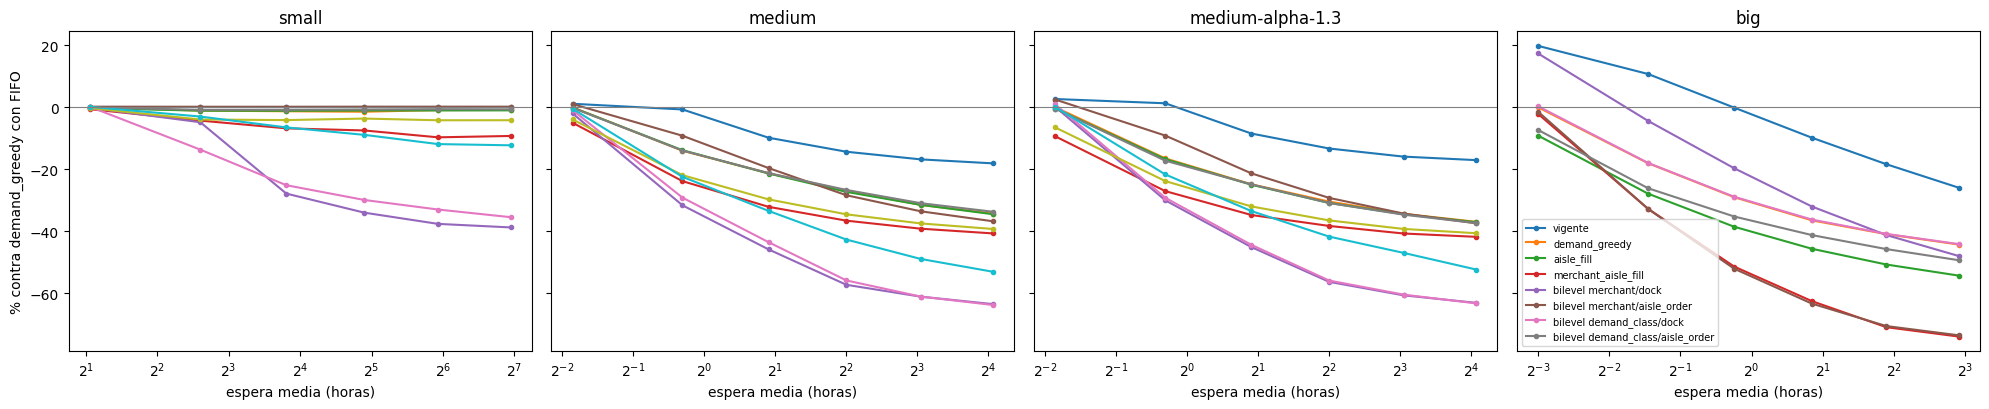

In [15]:
# Caminata contra espera media, un grafico por deposito, recorrido en S.
con_datos = [d for d in DEPOSITOS if d in set(A["dataset"])]
fig, axes = plt.subplots(1, len(con_datos), figsize=(5 * len(con_datos), 4.2), sharey=True)
for ax, d in zip(np.atleast_1d(axes), con_datos):
    datos = A.query("dataset == @d and routing == 's_shape'")
    for p in orden_planes:
        g = datos.query("plan == @p").sort_values("window")
        if len(g):
            ax.plot(g["wait_mean_min"] / 60, g["vs greedy FIFO"], marker="o", ms=3, label=p)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xscale("log", base=2)
    ax.set_title(d)
    ax.set_xlabel("espera media (horas)")
np.atleast_1d(axes)[0].set_ylabel("% contra demand_greedy con FIFO")
np.atleast_1d(axes)[-1].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

**Cambia el ranking segun el recorrido?** Posicion de cada plan (1 = el que menos camina) en cada
deposito, con FIFO y con ventana 4.

In [16]:
rk = A.query("window in (1, 4)").copy()
rk["posicion"] = rk.groupby(["dataset", "routing", "window"])["mean_distance"].rank(method="min").astype(int)
rk.pivot_table(index=["dataset", "plan"], columns=["window", "routing"], values="posicion", aggfunc="first").loc[
    [(d, p) for d in DEPOSITOS for p in orden_planes if (d, p) in set(zip(rk["dataset"], rk["plan"]))]]

window                                                  1             4      
routing                                           s_shape snake s_shape snake
dataset          plan                                                        
small            vigente                                8    10      10    10
                 demand_greedy                          6     3       6     8
                 linear_assignment                      2     2       7     5
                 aisle_fill                             1     7       3     4
                 merchant_aisle_fill                    4     9       1     2
                 bilevel merchant/dock                  8     8       9     9
                 bilevel merchant/aisle_order           8     5       2     1
                 bilevel demand_class/dock              5     1       8     6
                 bilevel demand_class/aisle_order       2     6       5     7
                 swap_search                            7     4       4     3
medium           vigente                               10    10      10    10
                 demand_greedy                          8     2       7     4
                 linear_assignment                      7     3       6     6
                 aisle_fill                             1     6       4     8
                 merchant_aisle_fill                    3     8       1     2
                 bilevel merchant/dock                  9     9       9     9
                 bilevel merchant/aisle_order           4     7       2     1
                 bilevel demand_class/dock              6     4       8     5
                 bilevel demand_class/aisle_order       2     5       5     7
                 swap_search                            5     1       3     3
medium-alpha-1.3 vigente                               10    10      10    10
                 demand_greedy                          5     2       8     4
                 linear_assignment                      3     3       6     5
                 aisle_fill                             1     5       3     7
                 merchant_aisle_fill                    7     9       1     3
                 bilevel merchant/dock                  9     8       9     9
                 bilevel merchant/aisle_order           8     7       2     1
                 bilevel demand_class/dock              4     4       7     6
                 bilevel demand_class/aisle_order       2     6       5     8
                 swap_search                            6     1       4     2
big              vigente                                8     8       8     8
                 demand_greedy                          5     2       5     4
                 aisle_fill                             1     4       3     3
                 merchant_aisle_fill                    3     6       2     2
                 bilevel merchant/dock                  7     7       7     7
                 bilevel merchant/aisle_order           4     5       1     1
                 bilevel demand_class/dock              6     1       6     5
                 bilevel demand_class/aisle_order       2     3       4     6

**El algoritmo de re-batching.** Cuanto baja la caminata la construccion sola y cuanto agregan los
intercambios, en la cuenta del algoritmo (recorrido en S), y cuanto tarda.

In [17]:
alg = A.query("routing == 's_shape' and window > 1").copy()
alg["construccion vs FIFO"] = 100 * (alg["static_construction"] / alg["static_fifo"] - 1)
alg["intercambios vs construccion"] = 100 * (alg["static_final"] / alg["static_construction"] - 1)
alg.groupby("window")[["construccion vs FIFO", "intercambios vs construccion", "batching_seconds"]].agg(["min", "median", "max"]).round(1)

construccion vs FIFO             intercambios vs construccion             batching_seconds             
                        min median  max                          min median  max              min median   max
window                                                                                                        
2                     -29.1  -14.3  0.0                         -4.2   -2.7  0.0              0.2    3.0   7.4
4                     -49.7  -22.8  0.0                         -4.4   -2.6  0.0              0.2    2.7   7.7
8                     -61.7  -28.4  0.0                         -5.1   -2.7  0.0              0.2    2.6   9.4
16                    -68.5  -31.9  0.1                         -8.2   -2.9  0.0              0.2    2.8   8.3
32                    -70.6  -34.0  0.2                        -12.6   -3.1  0.0              0.3    3.0  10.3

**Estabilidad en el tiempo.** El test cubre unas cinco semanas. Para cada semana se calcula la caminata
media de cada plan y su diferencia contra `demand_greedy` con FIFO en esa misma semana. Si una ventaja
fuera producto de pocas semanas, aca se veria.

In [18]:
bat = load_batches(OUT)
claves = A.query("routing == 's_shape' and window in (1, 4)")[["task", "eval", "dataset", "plan", "window"]]
bat = bat.merge(claves, on=["task", "eval"])
bat["semana"] = bat["timestamp"].dt.to_period("W")
semanal = bat.groupby(["dataset", "plan", "window", "semana"])["distance"].mean().rename("media").reset_index()
base_sem = semanal.query("plan == 'demand_greedy' and window == 1").set_index(["dataset", "semana"])["media"]
semanal["vs greedy FIFO"] = 100 * (semanal["media"] / semanal.set_index(["dataset", "semana"]).index.map(base_sem) - 1)
(semanal.groupby(["dataset", "plan", "window"])["vs greedy FIFO"].agg(["min", "median", "max", "count"])
        .rename(columns={"count": "semanas"}).round(1).unstack("window"))

min       median         max       semanas   
window                                                1     4      1     4     1     4       1  4
dataset          plan                                                                            
big              aisle_fill                        -9.6 -38.8   -9.2 -38.5  -8.8 -38.3       6  6
                 bilevel demand_class/aisle_order  -7.7 -35.5   -7.4 -35.3  -6.7 -34.9       6  6
                 bilevel demand_class/dock         -0.0 -29.0    0.2 -28.9   1.1 -28.7       6  6
                 bilevel merchant/aisle_order      -2.1 -52.6   -1.6 -52.0  -0.6 -51.7       6  6
                 bilevel merchant/dock             16.5 -19.9   17.4 -19.7  19.2 -19.2       6  6
                 demand_greedy                      0.0 -29.9    0.0 -29.0   0.0 -28.8       6  6
                 merchant_aisle_fill               -2.4 -51.7   -2.1 -51.4  -1.6 -50.2       6  6
                 vigente                           19.3  -0.6   19.8  -0.1  21.3   1.0       6  6
medium           aisle_fill                        -6.9 -32.7   -4.9 -32.1  -4.4 -31.7       6  6
                 bilevel demand_class/aisle_order  -6.1 -31.5   -3.9 -29.7  -3.4 -29.0       6  6
                 bilevel demand_class/dock         -0.4 -22.7   -0.1 -21.2   0.4 -20.6       6  6
                 bilevel merchant/aisle_order      -1.2 -43.9   -1.0 -43.5  -0.4 -43.1       6  6
                 bilevel merchant/dock              0.5 -20.3    1.0 -19.7   1.6 -19.0       6  6
                 demand_greedy                      0.0 -21.6    0.0 -21.2   0.0 -20.3       6  6
                 linear_assignment                 -0.8 -22.3   -0.3 -21.1   0.9 -20.5       6  6
                 merchant_aisle_fill               -2.4 -46.7   -2.2 -45.7  -0.8 -45.5       6  6
                 swap_search                       -0.8 -34.4   -0.6 -33.5   0.1 -32.6       6  6
                 vigente                            0.8 -10.6    1.0  -9.8   1.6  -9.5       6  6
medium-alpha-1.3 aisle_fill                       -10.6 -35.1   -9.1 -34.6  -8.2 -34.5       6  6
                 bilevel demand_class/aisle_order  -7.7 -32.3   -6.6 -32.0  -5.2 -31.6       6  6
                 bilevel demand_class/dock         -1.3 -26.8   -0.5 -24.9   0.0 -24.1       6  6
                 bilevel merchant/aisle_order      -0.6 -45.0    0.8 -44.2   1.5 -43.6       6  6
                 bilevel merchant/dock              2.0 -21.9    2.4 -21.4   2.8 -20.4       6  6
                 demand_greedy                      0.0 -25.9    0.0 -25.0   0.0 -24.3       6  6
                 linear_assignment                 -1.4 -25.8   -0.4 -24.8  -0.1 -23.8       6  6
                 merchant_aisle_fill               -1.1 -46.2    0.0 -45.2   0.9 -44.3       6  6
                 swap_search                       -0.4 -34.6   -0.2 -33.3   0.9 -32.4       6  6
                 vigente                            2.1  -9.3    2.6  -8.4   2.9  -7.9       6  6
small            aisle_fill                        -1.3 -12.3   -0.6  -5.7  -0.1  -2.7       6  6
                 bilevel demand_class/aisle_order  -0.6  -8.5   -0.4  -3.1   0.1  -1.9       6  6
                 bilevel demand_class/dock         -0.3  -1.0    0.0  -0.8   0.3  -0.5       6  6
                 bilevel merchant/aisle_order       0.0 -26.5    0.2 -25.6   0.3 -23.2       6  6
                 bilevel merchant/dock              0.0   0.0    0.2   0.1   0.3   0.3       6  6
                 demand_greedy                      0.0  -2.5    0.0  -0.8   0.0  -0.5       6  6
                 linear_assignment                 -0.4  -2.7   -0.2  -0.8   0.0   0.0       6  6
                 merchant_aisle_fill               -0.3 -29.8   -0.1 -27.1   0.0 -26.7       6  6
                 swap_search                       -0.2 -10.1    0.1  -6.3   0.3  -2.9       6  6
                 vigente                            0.0   0.0    0.2   0.2   0.3   0.3       6  6

## 6. Bloque B: definicion de frecuencia

Diferencia contra `demand_greedy` con `pick_lines` y FIFO (la referencia de siempre), recorrido en S.
Las filas `pick_lines` vienen del bloque A.

In [19]:
B = pd.concat([res.query("block == 'B'"),
               res.query("block == 'A' and routing == 's_shape' and window in (1, 4, 16) and plan in ('demand_greedy', 'aisle_fill', 'merchant_aisle_fill')")])
B.pivot_table(index=["dataset", "plan", "demand_metric"], columns="window", values="vs greedy FIFO").round(1)

window                                                1     4     16
dataset          plan                demand_metric                  
big              aisle_fill          pick_lines     -9.1 -38.5 -50.7
                                     total_units    -9.0 -38.3 -50.6
                                     unique_batches -9.1 -38.5 -50.7
                                     unique_orders  -9.1 -38.5 -50.7
                 demand_greedy       pick_lines      0.0 -29.0 -40.9
                                     total_units     0.5 -28.9 -40.9
                                     unique_batches  0.5 -28.9 -40.9
                                     unique_orders   0.0 -29.0 -40.9
                 merchant_aisle_fill pick_lines     -2.1 -51.4 -70.9
                                     total_units    -2.3 -51.3 -70.8
                                     unique_batches -1.7 -51.3 -70.9
                                     unique_orders  -2.1 -51.4 -70.9
medium           aisle_fill          pick_lines     -5.0 -32.1 -39.2
                                     total_units    -4.9 -31.7 -39.2
                                     unique_batches -5.0 -32.2 -39.2
                                     unique_orders  -5.0 -32.1 -39.2
                 demand_greedy       pick_lines      0.0 -21.3 -31.5
                                     total_units     0.0 -21.3 -31.1
                                     unique_batches -0.1 -21.3 -31.5
                                     unique_orders   0.0 -21.3 -31.5
                 merchant_aisle_fill pick_lines     -2.0 -45.9 -61.1
                                     total_units    -1.8 -45.9 -60.9
                                     unique_batches -1.6 -46.3 -61.5
                                     unique_orders  -2.0 -45.9 -61.1
medium-alpha-1.3 aisle_fill          pick_lines     -9.4 -34.8 -40.7
                                     total_units    -8.6 -34.6 -40.5
                                     unique_batches -9.4 -34.8 -40.6
                                     unique_orders  -9.4 -34.8 -40.7
                 demand_greedy       pick_lines      0.0 -24.9 -34.4
                                     total_units    -0.2 -24.5 -34.5
                                     unique_batches -0.2 -24.7 -34.3
                                     unique_orders   0.0 -24.9 -34.4
                 merchant_aisle_fill pick_lines      0.1 -45.1 -60.7
                                     total_units    -0.2 -46.1 -60.5
                                     unique_batches -0.1 -46.1 -61.1
                                     unique_orders   0.1 -45.1 -60.7
small            aisle_fill          pick_lines     -0.6  -6.8  -9.7
                                     total_units    -0.6  -6.7  -8.9
                                     unique_batches -0.6  -6.6  -9.6
                                     unique_orders  -0.6  -6.8  -9.7
                 demand_greedy       pick_lines      0.0  -1.3  -0.9
                                     total_units    -0.1  -1.1  -0.8
                                     unique_batches -0.1  -1.1  -0.7
                                     unique_orders   0.0  -1.3  -0.9
                 merchant_aisle_fill pick_lines     -0.2 -27.8 -37.6
                                     total_units    -0.1 -27.9 -37.6
                                     unique_batches -0.1 -27.9 -37.6
                                     unique_orders  -0.2 -27.8 -37.6

`unique_orders` da exactamente lo mismo que `pick_lines` en todos los casos. La razon esta en los
datos: ninguna orden pide el mismo SKU en dos lineas, asi que contar lineas y contar ordenes es lo
mismo.

In [20]:
from abs_affinity_based_slotting.config import dataset_dir

for d in DEPOSITOS:
    pe = pd.read_parquet(dataset_dir("v2", d) / "picking_events.parquet", columns=["order_id", "sku"])
    print(f"{d:17s} lineas por (orden, SKU), maximo:", pe.groupby(["order_id", "sku"]).size().max())

small             lineas por (orden, SKU), maximo: 1


medium            lineas por (orden, SKU), maximo: 1


medium-alpha-1.3  lineas por (orden, SKU), maximo: 1


big               lineas por (orden, SKU), maximo: 1


## 7. Bloque C: parametros de `swap_search`

Cada fila es la base o una variante que cambia un solo factor. Columnas: la ventana y el recorrido, como
diferencia contra `demand_greedy` con FIFO. Al final de cada deposito, como referencia, los planes
rapidos del bloque A en las mismas columnas. `segundos` es lo que tardo en calcularse el plan.

In [21]:
C = res.query("slot_method == 'swap_search' and window in (1, 4, 16)").copy()
C["fila"] = C["factor"] + " " + C["valor"]
ref_rapidos = res.query("block == 'A' and window in (1, 4, 16) and plan in ('demand_greedy', 'aisle_fill', 'merchant_aisle_fill')").copy()
ref_rapidos["fila"] = "(ref) " + ref_rapidos["plan"]
ref_rapidos = ref_rapidos[ref_rapidos["dataset"].isin(CON_QAP)]
tc = pd.concat([C, ref_rapidos]).pivot_table(index=["dataset", "fila"], columns=["routing", "window"], values="vs greedy FIFO").round(1)
tc["segundos"] = pd.concat([C, ref_rapidos]).groupby(["dataset", "fila"])["plan_seconds"].first().round(1)
tc

routing                                           s_shape             snake             segundos
window                                                  1     4    16     1     4    16         
dataset          fila                                                                           
medium           (ref) aisle_fill                    -5.0 -32.1 -39.2   4.0 -11.6 -16.8      0.0
                 (ref) demand_greedy                  0.0 -21.3 -31.5   0.0 -12.3 -19.1      0.0
                 (ref) merchant_aisle_fill           -2.0 -45.9 -61.1  11.5 -25.4 -43.2      0.0
                 base                                -0.5 -33.4 -48.9  -1.4 -21.7 -36.0   2068.5
                 distancia D walking                 -0.4 -27.5 -37.8   0.4 -15.9 -23.6   1828.1
                 filtro mutual_top_k:10              -0.5 -32.0 -41.1  -1.3 -21.0 -27.5   1056.8
                 filtro none                          0.1 -36.4 -53.9  -0.1 -25.2 -43.0  27545.4
                 filtro top_k:20                      0.1 -39.5 -55.5  -0.7 -28.4 -44.4   8496.4
                 filtro top_k:5                      -0.5 -33.7 -43.0  -0.1 -18.9 -25.8   1042.8
                 frecuencia unique_orders            -0.5 -33.4 -48.9  -1.4 -21.7 -36.0   1904.1
                 lambda 0.0                          -0.4 -35.6 -51.1  10.0 -17.0 -31.7   1575.4
                 lambda 0.25                         -0.6 -35.0 -49.1  -1.6 -24.5 -36.5   2529.7
                 lambda 0.75                         -0.4 -33.0 -42.6  -1.3 -21.8 -29.0   2103.4
                 metrica de afinidad cooccurrence    -1.9 -33.5 -40.1   1.0 -17.1 -23.0  24194.9
                 metrica de afinidad cosine          -0.4 -34.8 -49.6  -0.7 -23.0 -37.2   5241.4
                 normalizacion False                 -0.8 -25.8 -35.5  -1.0 -15.6 -22.9   4053.0
                 plan inicial aisle_fill             -2.6 -41.2 -56.3   4.1 -23.3 -40.5   2832.4
                 plan inicial merchant_aisle_fill    -0.8 -43.8 -60.9   4.9 -27.8 -46.0   2008.2
                 unidad de co-ocurrencia batch_id    -0.2 -25.4 -35.3   1.5 -12.7 -19.1   4280.0
                 vecindad neighbor                    0.1 -24.7 -34.4   3.0 -11.7 -19.1     39.4
medium-alpha-1.3 (ref) aisle_fill                    -9.4 -34.8 -40.7   3.2 -10.6 -15.1      0.0
                 (ref) demand_greedy                  0.0 -24.9 -34.4   0.0 -13.4 -20.3      0.0
                 (ref) merchant_aisle_fill            0.1 -45.1 -60.7  20.8 -20.1 -40.8      0.0
                 base                                 0.1 -33.5 -47.0  -0.4 -21.1 -31.5   3414.1
                 distancia D walking                  0.2 -28.3 -37.7   4.1 -12.6 -19.4   2501.2
                 filtro mutual_top_k:10               0.1 -31.3 -41.1  -0.1 -18.9 -25.6    696.8
                 filtro none                          0.7 -35.0 -52.3   0.9 -21.2 -37.2  22190.2
                 filtro top_k:20                      1.3 -33.3 -49.3   0.4 -22.6 -37.3  11782.2
                 filtro top_k:5                      -0.7 -35.9 -46.5  -0.1 -20.6 -30.0    985.3
                 frecuencia unique_orders             0.1 -33.5 -47.0  -0.4 -21.1 -31.5   2981.0
                 lambda 0.0                           0.2 -35.1 -48.8  16.4 -11.0 -25.0   1895.0
                 lambda 0.25                          0.4 -35.0 -49.3   0.1 -22.3 -34.5   4008.8
                 lambda 0.75                         -0.2 -32.4 -43.5  -0.6 -18.8 -27.5   3268.5
                 metrica de afinidad cooccurrence    -3.8 -33.7 -40.5   1.4 -14.1 -20.1  16821.2
                 metrica de afinidad cosine           0.7 -38.1 -53.9   0.0 -25.0 -39.7   6422.4
                 normalizacion False                 -1.2 -26.8 -35.8  -0.3 -15.0 -22.2   3645.5
                 plan inicial aisle_fill             -2.9 -39.6 -52.2   4.3 -19.8 -34.3   5124.9
                 plan inicial merchant_aisle_fill     1.0 -42.6 -60.1   8.5 -25.6 -45.3   1902.5
                 unidad

Los terminos del objetivo de cada plan de `swap_search`, $L$ y $Q$, comparados con su plan inicial. Solo
se pueden comparar dentro de una misma instancia (cada variante de instancia tiene sus propios $f$, $a$
y $D$), asi que se muestra el cambio relativo respecto del plan inicial calculado en la misma instancia.

In [22]:
# L y Q del plan inicial en cada instancia, recalculados con la misma instancia de cada variante.
from abs_affinity_based_slotting.experiments import context, build_plan
from abs_affinity_based_slotting.slotting import slotting_cost

filas_lq = []
for (d, fila), g in C.groupby(["dataset", "fila"]):
    r = g.iloc[0]
    if r["slot_lam"] is None or np.isnan(r["slot_lam"]):
        continue
    spec = InstanceSpec(d, r["demand_metric"], r["affinity_metric"], r["cooccurrence_col"], r["affinity_filter"],
                        bool(r["normalize"]), r["pair_distance"])
    ctx = context(spec)
    inicial = build_plan(ctx, SlottingSpec(r["slot_seed"]))
    L0, Q0 = slotting_cost(inicial, ctx.instance, lam=1.0), slotting_cost(inicial, ctx.instance, lam=0.0)
    filas_lq.append({"dataset": d, "fila": fila, "L vs inicial (%)": 100 * (r["plan_L"] / L0 - 1),
                     "Q vs inicial (%)": 100 * (r["plan_Q"] / Q0 - 1) if Q0 > 0 else np.nan})
pd.DataFrame(filas_lq).set_index(["dataset", "fila"]).round(1)

L vs inicial (%)  Q vs inicial (%)
dataset          fila                                                                
medium           base                                           3.1             -83.2
                 distancia D walking                            6.5             -70.3
                 filtro mutual_top_k:10                         2.8             -94.4
                 filtro none                                   15.8             -88.1
                 filtro top_k:20                               15.4             -89.7
                 filtro top_k:5                                 3.7             -85.1
                 frecuencia unique_orders                       3.1             -83.2
                 lambda 0.0                                    26.1             -84.0
                 lambda 0.25                                    3.0             -83.9
                 lambda 0.75                                    2.5             -80.9
                 metrica de afinidad cooccurrence               5.7             -45.9
                 metrica de afinidad cosine                     8.5             -73.6
                 normalizacion False                            0.0             -48.7
                 plan inicial aisle_fill                       -6.3             -78.7
                 plan inicial merchant_aisle_fill             -26.2             -17.4
                 unidad de co-ocurrencia batch_id               3.5             -41.1
                 vecindad neighbor                              7.3             -27.9
medium-alpha-1.3 base                                           3.8             -78.8
                 distancia D walking                            7.5             -66.5
                 filtro mutual_top_k:10                         3.1             -93.8
                 filtro none                                   18.6             -83.8
                 filtro top_k:20                               15.2             -84.5
                 filtro top_k:5                                 4.1             -85.4
                 frecuencia unique_orders                       3.8             -78.8
                 lambda 0.0                                    31.7             -80.5
                 lambda 0.25                                    4.6             -81.7
                 lambda 0.75                                    3.3             -79.9
                 metrica de afinidad cooccurrence               6.7             -48.0
                 metrica de afinidad cosine                    12.6             -75.6
                 normalizacion False                            0.0             -41.9
                 plan inicial aisle_fill                       -6.3             -71.9
                 plan inicial merchant_aisle_fill             -26.5             -27.3
                 unidad de co-ocurrencia batch_id               3.7             -38.5
                 vecindad neighbor                              8.0             -27.6
small            base                                           2.7             -84.4
                 distancia D walking                            4.2             -53.9
                 filtro mutual_top_k:10                         1.7             -86.3
                 filtro none                                    5.6             -71.5
                 filtro top_k:20                                4.6             -83.4
                 filtro top_k:5                                 1.5             -69.4
                 frecuencia unique_orders                       2.7             -84.4
                 lambda 0.0                                    34.2             -91.3
                 lambda 0.25                                    4.8             -85.5
                 lambda 0.75                                    1.7             -80.1
                 metrica de afinidad cooccurrence               3.3             -34.1
         

## 8. Bloque D: politica de reposicion

Diferencia contra `demand_greedy` con FIFO y reposicion `home`, recorrido en S. Al lado, cuantas
reposiciones fueron a otra ubicacion que la del plan (mudanzas) y que fraccion de los SKUs termino el
test fuera de su ubicacion del plan.

In [23]:
D = res.query("block == 'D'")
pd.concat({"vs greedy FIFO": D.pivot_table(index=["dataset", "plan", "replenishment"], columns="window", values="vs greedy FIFO").round(1),
           "mudanzas": D.pivot_table(index=["dataset", "plan", "replenishment"], columns="window", values="relocations"),
           "fuera del plan al final": D.pivot_table(index=["dataset", "plan", "replenishment"], columns="window", values="final_off_home").round(2)},
          axis=1)

vs greedy FIFO       mudanzas          fuera del plan al final      
window                                                             1     4        1        4                       1     4
dataset          plan                replenishment                                                                        
big              aisle_fill          home                       -9.1 -38.5      0.0      0.0                    0.00  0.00
                                     objective_greedy           -8.6 -36.4    429.0    448.0                    0.02  0.02
                                     random                     12.8   3.7  15056.0  14214.0                    0.25  0.25
                 demand_greedy       home                        0.0 -29.0      0.0      0.0                    0.00  0.00
                                     objective_greedy            1.3 -20.0   3576.0   3501.0                    0.13  0.13
                                     random                     19.0  15.1  15056.0  14365.0                    0.25  0.25
                 merchant_aisle_fill home                       -2.1 -51.4      0.0      0.0                    0.00  0.00
                                     objective_greedy            6.0 -36.2   1064.0   1039.0                    0.04  0.04
                                     random                     18.2   9.5  15056.0  14160.0                    0.25  0.25
                 vigente             home                       19.8  -0.1      0.0      0.0                    0.00  0.00
                                     objective_greedy           15.2  11.3   9189.0   9090.0                    0.31  0.31
                                     random                     19.8  19.2  15056.0  14230.0                    0.25  0.25
medium           aisle_fill          home                       -5.0 -32.1      0.0      0.0                    0.00  0.00
                                     objective_greedy           -3.9 -26.0    371.0    392.0                    0.05  0.05
                                     random                      1.1  -1.4   6817.0   6300.0                    0.37  0.38
                 demand_greedy       home                        0.0 -21.3      0.0      0.0                    0.00  0.00
                                     objective_greedy           -0.0  -9.0   2018.0   2040.0                    0.25  0.26
                                     random                      1.1   0.9   6817.0   6321.0                    0.37  0.37
                 merchant_aisle_fill home                       -2.0 -45.9      0.0      0.0                    0.00  0.00
                                     objective_greedy           -0.2 -38.5    198.0    192.0                    0.02  0.02
                                     random                      1.1  -1.1   6817.0   6292.0                    0.37  0.37
                 vigente             home                        1.1  -9.8      0.0      0.0                    0.00  0.00
                                     objective_greedy            1.0   0.6   3715.0   3709.0                    0.42  0.42
                                     random                      1.1   1.1   6817.0   6338.0                    0.37  0.37
medium-alpha-1.3 aisle_fill          home                       -9.4 -34.8      0.0      0.0                    0.00  0.00
                                     objective_greedy           -8.4 -31.0    201.0    203.0                    0.03  0.03
                                     random                      2.4  -0.2   6845.0   6253.0                    0.33  0.33
                 demand_greedy       home                        0.0 -24.9      0.0      0.0                    0.00  0.00
                                     objective_greedy            0.3 -12.7   1643.0   1626.0                    0.21  0.21
                                     random                      2.7   2.3   6845.0   6177.0                    0.33  

## 9. Lectura

Salvo que se diga otra cosa, las cifras son con recorrido en S y reposicion `home`, como diferencia
contra `demand_greedy` con FIFO en el mismo deposito.

**Controles.** Las 138 tareas y las 948 evaluaciones terminaron sin errores. La simulacion coincide
con la cuenta del algoritmo y no hay mudanzas con `home`. Solo `big` tiene lineas sin stock, entre 1 y
25 por corrida.

**1. Con FIFO el slotting mueve poco.** El mejor plan con FIFO es `aisle_fill` en los cuatro
depositos: -0,6% en small, -5,0% en medium, -9,4% en medium-alpha-1.3 y -9,1% en big.
`linear_assignment`, el optimo exacto de $L$, queda a 0,4% o menos de `demand_greedy`. `swap_search`
con la configuracion base queda entre -0,5% y +0,1%.

**2. El re-batching mejora con cualquier slotting, a cambio de espera.** Solo con re-armar los batches
de `demand_greedy` y ventana 4, la caminata baja 1,3% en small, 21,3% en medium, 24,9% en
medium-alpha-1.3 y 29,0% en big. Con esa ventana la espera media de una orden es de 113 minutos en
medium y 51 en big, donde sale un batch mas seguido. En small es de 840 minutos, porque ahi sale un
batch cada mucho mas tiempo, y es ademas donde menos se gana: un batch FIFO ya entra a 3,97 de los 4
pasillos y re-armar lo baja solo a 3,80.

**3. Con re-batching gana agrupar por merchant y llenar pasillos.** `merchant_aisle_fill` y su version
con solver, `bilevel merchant/aisle_order`, son los dos primeros con ventana 4 o mas en los cuatro
depositos. En medium, medium-alpha-1.3 y big quedan a menos de 3 puntos entre si; en small,
`merchant_aisle_fill` le saca hasta 4,6.

| deposito | `merchant_aisle_fill`, $W = 4$ | `bilevel merchant/aisle_order`, $W = 4$ | `merchant_aisle_fill`, $W = 32$ |
|---|---|---|---|
| small | -27,8% | -25,1% | -38,8% |
| medium | -45,9% | -43,5% | -63,5% |
| medium-alpha-1.3 | -45,1% | -44,4% | -63,1% |
| big | -51,4% | -52,1% | -74,0% |

Los batches de medium pasan de 7,63 pasillos (`demand_greedy` con FIFO) a 3,55 con ventana 4 y 1,92
con ventana 32; los de big, de 12,62 a 5,38 y 2,29. Si los bloques de cada merchant se arman por
distancia al dock en vez de por pasillos (`bilevel merchant/dock`), la ganancia en medium con
ventana 4 cae a -19,6%: los bloques tienen que ser pasillos.

**4. El recorrido cambia el ranking con FIFO, no con re-batching.** Con `snake` y FIFO,
`merchant_aisle_fill` camina mas que `demand_greedy`: +8,6% en small, +11,5% en medium, +20,8% en
medium-alpha-1.3 y +7,7% en big. Los primeros son `bilevel demand_class/dock` (small y big) y
`swap_search` (los dos medium). Con ventana 4, en cambio, `bilevel merchant/aisle_order` queda primero
con `snake` en los cuatro depositos y `merchant_aisle_fill` segundo o tercero. Las ganancias con
`snake` son menores: en medium con ventana 4, -27,2% y -25,4%, contra -12,3% de `demand_greedy`.

**5. `swap_search` no supera a la regla de merchants.** En medium la base gana 33,4% con ventana 4 y
48,9% con ventana 16, y tarda 2.069 segundos. Las variantes que mas ayudan:

- Arrancar de `aisle_fill` la lleva a -41,2% y -56,3%, mucho mejor que `aisle_fill` solo (-32,1% y
  -39,2%).
- Arrancar de `merchant_aisle_fill` da -43,8% y -60,9%, casi lo mismo que la regla sola (-45,9% y
  -61,1%).
- El filtro `top_k:20` da -39,5% y -55,5%, pero tarda 8.496 segundos; `none` da -36,4% y -53,9% y tarda
  27.545.

Las que mas empeoran respecto de la base: co-ocurrencia por batch (-25,4% y -35,3%), sin
normalizar (-25,8% y -35,5%), vecindad `neighbor` (-24,7% y -34,4%) y distancia `walking` (-27,5% y
-37,8%). $\lambda = 0$ gana en S (-35,6% y -51,1%) pero sube $L$ un 26,1% y con `snake` y FIFO camina
10,0% mas. En medium-alpha-1.3 y small el patron es el mismo, y ninguna variante alcanza a
`merchant_aisle_fill`: la mejor de medium-alpha-1.3 da -42,6% y -60,1% contra -45,1% y -60,7%, y la
de small -18,5% y -28,1% contra -27,8% y -37,6%.

**6. La definicion de frecuencia no cambia nada.** Las cuatro difieren en 1 punto o menos en todas las
combinaciones, y `unique_orders` es identica a `pick_lines`.

**7. Sin mantener el plan, la ganancia desaparece.** Con reposicion `random`, la de los datos, todos
los planes quedan cerca del vigente: en medium con ventana 4, entre -1,4% y +1,1%, y al final del test
el 37 o 38% de los SKUs esta fuera de su ubicacion del plan. `objective_greedy` conserva buena parte:
`merchant_aisle_fill` con ventana 4 da -38,5%, contra -45,9% con `home`.

**8. Los resultados son estables en el tiempo.** En las 6 semanas de test, `merchant_aisle_fill` con
ventana 4 va de -46,7% a -45,5% en medium y de -51,7% a -50,2% en big. Small varia mas: `aisle_fill`
con ventana 4 va de -12,3% a -2,7%.

**9. El algoritmo de re-batching.** Con ventana 4, la construccion baja la caminata 22,8% en la
mediana de las corridas, y los intercambios agregan una mediana de 2,6% y como mucho 4,4%. Re-armar
todo el test tarda una mediana de 2,7 segundos.

**Conclusion.** La combinacion que mejor funciona en todos los depositos es agrupar cada merchant en
pasillos (`merchant_aisle_fill`, o `bilevel merchant/aisle_order`), re-armar los batches juntando
ordenes que comparten pasillos, y reponer siempre a la ubicacion del plan. La ventana es la decision
de la operacion: con 1,9 horas de espera media en medium la caminata baja 46%. `swap_search` no aporta
sobre esa regla con estos datos, y en medium su configuracion base tarda 35 minutos por plan.

**Lo que este notebook no mide.** La congestion de pickers en un mismo pasillo; la espera con horas
de llegada reales, que los datos no traen; merchants con demandas muy distintas entre si; y el
costo de mudar el deposito al plan nuevo.